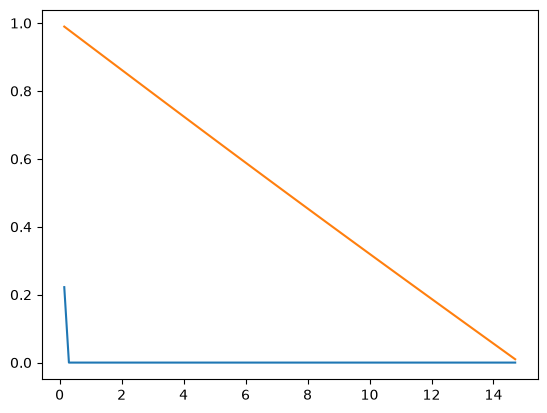

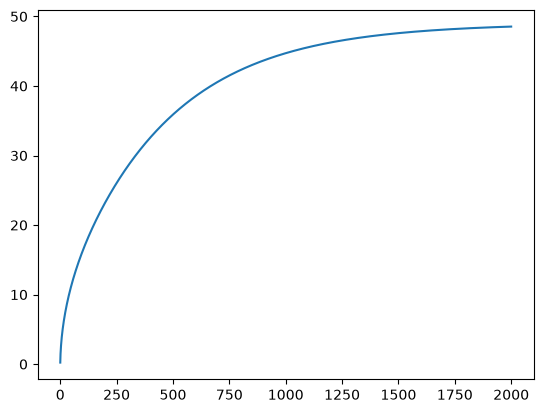

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
N = 100          # Total number of grid points
dt = 0.1         # Temporal step size
dx = 0.15        # Spatial step size
D = 0.05         # Diffusion constant
L = N * dx       # System size
t_end = 2000      # Final time

# Initialize arrays
rho = np.zeros(N)       # Concentration field 
rho_0 = np.zeros(N)     # Initial concentration field
rho_temp = np.zeros(N)  # temporary concentration-field vector 

# Spatial and temporal vectors
x = np.arange(0, L, dx) # site vector
t = np.arange(dt, t_end, dt) # time vector

# Initial condition
#rho_0 = np.exp(-((x - L/2)/5)**2)

# Initialize concentration field
rho = rho_0.copy()

rho_T = np.zeros((N, len(t))) # Array to store concentration at different time points
n = np.zeros(len(t)) # Total no. of particles

for i in range(len(t)):

    '''
    # No-flux(Neumann) boundary conditions
    rho[-1] = rho[-2]
    rho[0] = rho[1]
    '''
    
    # Dirichlet boundary conditions
    rho[0]=1
    rho[-1]=0
    

    # Update concentration at interior grid points
    for p in range(1, N-1):

        rho_temp[p] =(rho[p] + D * dt /(dx * dx) *(rho[p+1] + rho[p-1] - 2*rho[p]))
        
    # Update concentration field
    rho = rho_temp.copy() # use .copy() to create separate memory space for rho and rho_temp
    #rho[1:N-2]=rho_temp[1:N-2]

    # Store concentration profile
    rho_T[:, i] = rho

    # Total concentration
    n[i] = np.sum(rho[1:-1])

plt.plot(x[1:-1], rho_T[1:-1, 0])
plt.plot(x[1:-1], rho_T[1:-1, len(t)-1])

plt.figure()
plt.plot(t,n)


 Diffusion Courant number C = 0.22222222222222227( Must be <= 0.5 for stability )


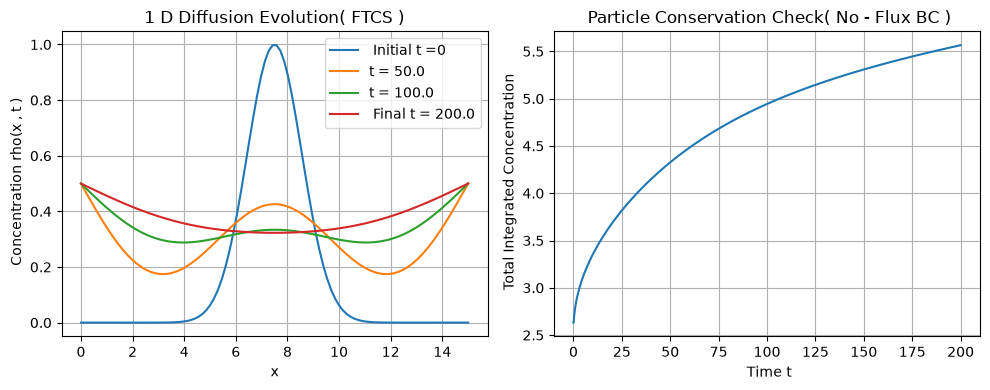

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# P a r a m ete rs
N = 100 # Number of grid points
dx = 0.15 # Spatial reso lut ion
L = N * dx # System size
D = 0.05 # Diffusion c o e f f i c i e n t
dt = 0.1 # Temporal step( Check stability : D * dt / dx ^2 = 0.222 <= 0.5)
t_end = 200.0 # Final s imu lati on time

# St abi lity v e r i f i c a t i o n
C = D * dt /( dx **2)
print( f" Diffusion Courant number C = { C}( Must be <= 0.5 for stability )" )
assert C <= 0.5 ," Stability condition violated : D * dt / dx ^2 > 0.5!"

# Spatial and temporal vectors
x = np.linspace(0 , L , N )
t = np.arange(0 , t_end + dt , dt )

# Initial condition : centered Gaussian c o n c e n t r a t i o n pulse
rho_0 = np.exp( -(( x - L /2) / 1.5) **2)
rho = rho_0.copy()
rho_temp = np.zeros( N )

# Storage for space - time evolution and particle c o n s e r v a t i o n
rho_history =[ rho.copy() ]
total_particles =[ np.sum( rho[1: -1]) * dx ]

# FTCS Time Stepping
for n in range(1 , len( t ) ) :
    # Interior update using FTCS
    for i in range(1 , N - 1) :
        rho_temp[ i ] = rho[ i ] + C *( rho[ i +1] + rho[i -1] - 2 * rho[ i ])

    # Boundary Co ndit ion s( Choose one ) :
    #( A ) Neumann( No - Flux ) : rho[0] = rho[1] , rho[ -1] = rho[ -2]
    #rho_temp[0] = rho_temp[1]
    #rho_temp[ -1] = rho_temp[ -2]

    #( B ) Dirichlet : Uncomment for fixed boundary values
    rho_temp[0] = 0.5; rho_temp[ -1] = 0.5

    rho = rho_temp.copy()
    rho_history.append( rho.copy() )
    total_particles.append( np.sum( rho[1: -1]) * dx )

 # Plotting
plt.figure( figsize =(10 , 4) )
plt.subplot(1 , 2 , 1)
plt.plot(x , rho_0 , label =" Initial t =0")
plt.plot(x , rho_history[ len( t ) //4] , label = f"t = { t[ len( t ) //4] }")
plt.plot(x , rho_history[ len( t ) //2] , label = f"t = { t[ len( t ) //2] }")
plt.plot(x , rho  , label = f" Final t = { t_end }")
plt.xlabel("x")
plt.ylabel(" Concentration rho(x , t )")
plt.title("1 D Diffusion Evolution( FTCS )")
plt.legend()
plt.grid( True )

plt.subplot(1 , 2 , 2)
plt.plot(t , total_particles)
plt.xlabel(" Time t")
plt.xlabel(" Time t")
plt.xlabel(" Time t")
plt.ylabel(" Total Integrated Concentration")
plt.title(" Particle Conservation Check( No - Flux BC )")
plt.grid( True )
plt.tight_layout()
plt.show()